In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [14]:
from google.colab import files

uploaded = files.upload()

Saving online_courses_uses.csv to online_courses_uses (1).csv


In [15]:
file_name = next(iter(uploaded.keys()))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 10000
Number of columns: 9


,Course_ID,Course_Name,Category,Duration (hours),Enrolled_Students,Completion_Rate (%),Platform,Price ($),Rating (out of 5)
0,1,Course_1,Office Tools,21,4217,50.646827,Coursera,38.797425,4.811252
1,2,Course_2,Office Tools,57,4238,82.240240,edX,160.650991,3.829329
2,3,Course_3,Technology,52,2700,55.729028,LinkedIn Learning,123.503781,4.851950
3,4,Course_4,Office Tools,69,4308,58.664729,LinkedIn Learning,116.775704,3.913732
4,5,Course_5,Technology,43,4792,62.598147,Udemy,96.246696,4.921968


In [16]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Column Names:
['Course_ID', 'Course_Name', 'Category', 'Duration (hours)', 'Enrolled_Students', 'Completion_Rate (%)', 'Platform', 'Price ($)', 'Rating (out of 5)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Course_ID            10000 non-null  int64  
 1   Course_Name          10000 non-null  object 
 2   Category             10000 non-null  object 
 3   Duration (hours)     10000 non-null  int64  
 4   Enrolled_Students    10000 non-null  int64  
 5   Completion_Rate (%)  10000 non-null  float64
 6   Platform             10000 non-null  object 
 7   Price ($)            10000 non-null  float64
 8   Rating (out of 5)    10000 non-null  float64
dtypes: float64(3), int64(3), object(3)
memory usage: 703.3+ KB

Statistical Summary:


,Course_ID,Course_Name,Category,Duration (hours),Enrolled_Students,Completion_Rate (%),Platform,Price ($),Rating (out of 5)
count,10000.00000,10000,10000,10000.000000,10000.000000,10000.000000,10000,10000.000000,10000.000000
unique,NaN,10000,9,NaN,NaN,NaN,4,NaN,NaN
top,NaN,Course_9984,Business,NaN,NaN,NaN,Udemy,NaN,NaN
freq,NaN,1,1148,NaN,NaN,NaN,2554,NaN,NaN
mean,5000.50000,NaN,NaN,55.144000,2530.653000,75.119729,NaN,106.391332,3.994154
std,2886.89568,NaN,NaN,26.199242,1423.808243,14.462138,NaN,55.100685,0.575502
min,1.00000,NaN,NaN,10.000000,101.000000,50.008183,NaN,10.037145,3.000026
25%,2500.75000,NaN,NaN,32.000000,1289.000000,62.629516,NaN,58.613731,3.490250
50%,5000.50000,NaN,NaN,55.000000,2532.000000,75.156568,NaN,108.042392,4.002789
75%,7500.25000,NaN,NaN,78.000000,3764.000000,87.595268,NaN,153.945558,4.483662


In [17]:
# Remove duplicate rows
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Display missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Clean column names
df.columns = (
    df.columns.str.strip()
              .str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True)
              .str.strip("_")
)

print("\nCleaned column names:")
print(df.columns.tolist())

Duplicates before cleaning: 0

Missing values in each column:
Course_ID              0
Course_Name            0
Category               0
Duration (hours)       0
Enrolled_Students      0
Completion_Rate (%)    0
Platform               0
Price ($)              0
Rating (out of 5)      0
dtype: int64

Cleaned column names:
['course_id', 'course_name', 'category', 'duration_hours', 'enrolled_students', 'completion_rate', 'platform', 'price', 'rating_out_of_5']


In [18]:
aliases = {
    "course_name": ["course_name", "coursename", "title", "course_title"],
    "category": ["category", "course_category", "subject"],
    "platform": ["platform", "course_platform", "website"],
    "rating": ["rating", "average_rating", "course_rating"],
    "price": ["price", "price_usd", "course_price"],
    "enrolled_students": [
        "enrolled_students", "enrollment_count",
        "enrollments", "students_enrolled"
    ],
    "completion_rate": [
        "completion_rate", "completion_rate_percent",
        "completion_rate_pct"
    ]
}

rename_columns = {}

for standard_name, possible_names in aliases.items():
    for name in possible_names:
        if name in df.columns:
            rename_columns[name] = standard_name
            break

df = df.rename(columns=rename_columns)

print("Available columns:")
print(df.columns.tolist())

Available columns:
['course_id', 'course_name', 'category', 'duration_hours', 'enrolled_students', 'completion_rate', 'platform', 'price', 'rating_out_of_5']


In [19]:
print("Total number of courses:", len(df))

if "platform" in df.columns:
    print("\nCourses by platform:")
    display(df["platform"].value_counts())

if "category" in df.columns:
    print("\nCourses by category:")
    display(df["category"].value_counts())

if "rating" in df.columns:
    df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
    print("\nAverage course rating:", round(df["rating"].mean(), 2))

if "price" in df.columns:
    df["price"] = pd.to_numeric(df["price"], errors="coerce")
    print("Average course price:", round(df["price"].mean(), 2))

if "enrolled_students" in df.columns:
    df["enrolled_students"] = pd.to_numeric(
        df["enrolled_students"], errors="coerce"
    )
    print(
        "Total recorded enrolments:",
        int(df["enrolled_students"].sum())
    )

Total number of courses: 10000

Courses by platform:


,count
platform,
Udemy,2554
LinkedIn Learning,2501
edX,2479
Coursera,2466



Courses by category:


,count
category,
Business,1148
Office Tools,1139
Marketing,1126
Finance,1124
Design,1112
AI,1104
Data Science,1098
Programming,1076
Technology,1073


Average course price: 106.39
Total recorded enrolments: 25306530


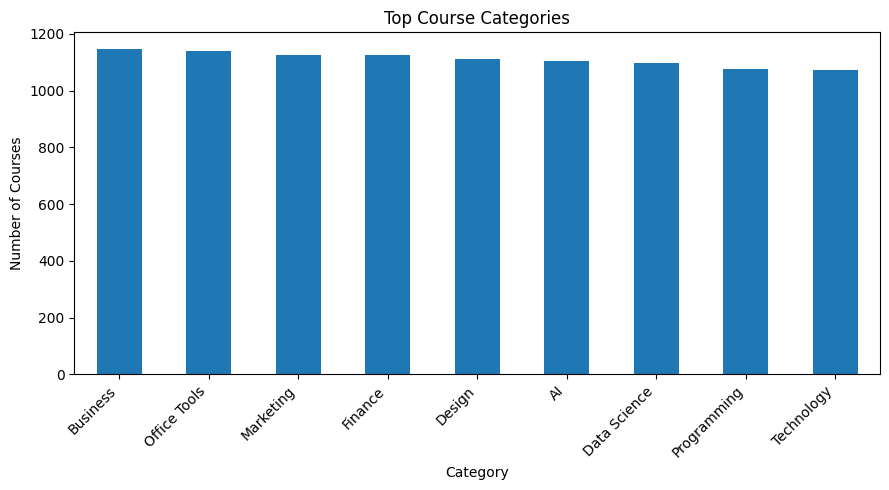

In [20]:
if "category" in df.columns:
    category_counts = df["category"].value_counts().head(10)

    category_counts.plot(kind="bar", figsize=(9, 5))
    plt.title("Top Course Categories")
    plt.xlabel("Category")
    plt.ylabel("Number of Courses")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Category column is unavailable in this dataset.")

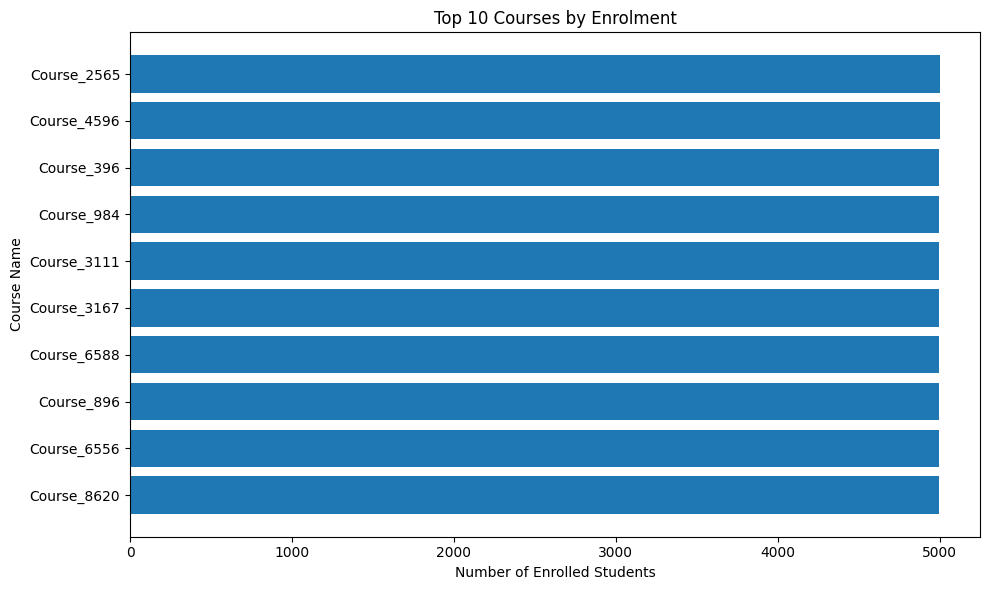

,course_name,enrolled_students
2564,Course_2565,5000
4595,Course_4596,5000
395,Course_396,4999
983,Course_984,4999
3110,Course_3111,4999
3166,Course_3167,4998
6587,Course_6588,4998
895,Course_896,4997
6555,Course_6556,4997
8619,Course_8620,4997


In [21]:
if {"course_name", "enrolled_students"}.issubset(df.columns):
    top_courses = df.nlargest(10, "enrolled_students")

    plt.figure(figsize=(10, 6))
    plt.barh(
        top_courses["course_name"].astype(str),
        top_courses["enrolled_students"]
    )
    plt.title("Top 10 Courses by Enrolment")
    plt.xlabel("Number of Enrolled Students")
    plt.ylabel("Course Name")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    display(top_courses[["course_name", "enrolled_students"]])
else:
    print("Course name or enrolment column is unavailable.")

In [22]:
if {"platform", "rating"}.issubset(df.columns):
    platform_ratings = (
        df.groupby("platform")["rating"]
          .mean()
          .dropna()
          .sort_values(ascending=False)
    )

    platform_ratings.plot(kind="bar", figsize=(8, 5))
    plt.title("Average Rating by Platform")
    plt.xlabel("Platform")
    plt.ylabel("Average Rating")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    display(platform_ratings)
else:
    print("Platform or rating column is unavailable.")

Platform or rating column is unavailable.


In [23]:
if {"price", "rating"}.issubset(df.columns):
    plt.figure(figsize=(8, 5))
    plt.scatter(df["price"], df["rating"], alpha=0.6)
    plt.title("Course Price vs Rating")
    plt.xlabel("Course Price")
    plt.ylabel("Course Rating")
    plt.tight_layout()
    plt.show()
else:
    print("Price or rating column is unavailable.")

Price or rating column is unavailable.


In [24]:
print("PROJECT: ONLINE COURSE AND LEARNING PLATFORM ANALYSIS")
print("-" * 55)
print("Total records analysed:", len(df))

if "rating" in df.columns:
    print("Average rating:", round(df["rating"].mean(), 2))

if "price" in df.columns:
    print("Average price:", round(df["price"].mean(), 2))

if "platform" in df.columns:
    print("\nPlatform distribution:")
    print(df["platform"].value_counts().to_string())

print("\nAnalysis completed successfully.")

PROJECT: ONLINE COURSE AND LEARNING PLATFORM ANALYSIS
-------------------------------------------------------
Total records analysed: 10000
Average price: 106.39

Platform distribution:
platform
Udemy                2554
LinkedIn Learning    2501
edX                  2479
Coursera             2466

Analysis completed successfully.
